In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)  # don't truncate long cell contents

In [2]:
import re
from concurrent.futures import ThreadPoolExecutor
from glob import glob
from os.path import basename, dirname

# ---------------------------------------------------------------- parsing ---

_FIELD_RE = re.compile(r"^\s*([A-Za-z][^:]*?)\s*:\s*(.*?)\s*$")
_MISSING = {"", "-", "n/a", "na", "none", "null"}


def _to_bool(v):
    return v.strip().lower() in {"yes", "true", "1"}


def _to_seconds(v):
    return float(v.split()[0])


# report label -> (dict key, caster)
_FIELDS = {
    "Item Index":                          ("item_index", int),
    "JSON Path":                           ("json_path", str),
    "Embedding Path":                      ("embedding_path", str),
    "JSON Valid":                          ("json_valid", _to_bool),
    "Sequence Similarity (Gestalt)*":      ("sequence_similarity", float),
    "Levenshtein Distance (minified)":     ("levenshtein_distance", int),
    "Levenshtein Similarity (minified)*":  ("levenshtein_similarity", float),
    "App Match":                           ("app_match", _to_bool),
    "Activity Match":                      ("activity_match", _to_bool),
    "Component Count (GT)":                ("component_count_gt", int),
    "Component Count (Pred)":              ("component_count_pred", int),
    "Class Accuracy*":                     ("class_accuracy", float),
    "Average Bounds IoU*":                 ("average_bounds_iou", float),
    "Execution Time":                      ("execution_time", _to_seconds),
}


def parse_metrics_from_report_file(path):
    """Parse an evaluation report into a flat dict of metrics.

    The side-by-side JSON dump is skipped entirely; missing or unparsable
    values become None so every report yields the same set of keys.
    """
    with open(path, "r", encoding="utf-8", errors="replace") as fh:
        text = fh.read()

    # header (above the JSON table) + everything below "METRICS:"
    head, sep, tail = text.partition("GROUND TRUTH")
    relevant = head + tail.partition("METRICS:")[2] if sep else text

    out = {key: None for key, _ in _FIELDS.values()}
    for line in relevant.splitlines():
        match = _FIELD_RE.match(line)
        if match is None:
            continue
        label, raw = match.group(1), match.group(2)
        if label not in _FIELDS:
            continue
        key, cast = _FIELDS[label]
        if raw.lower() in _MISSING:
            continue
        try:
            out[key] = cast(raw)
        except (ValueError, IndexError):
            out[key] = None
    return out


def _process_report(g):
    # e.g. "reconstructions_4096_avg/0_report.txt" -> "4096_avg"
    # e.g. "reconstructions_4096_last/0_report.txt" -> "4096_last"
    # keeping the pooling suffix (avg/last) in the key prevents the
    # 4096_avg and 4096_last folders from clobbering each other.
    dimensions = dirname(g).removeprefix("reconstructions_")
    idx = basename(g).split("_")[0]
    return (dimensions, idx), parse_metrics_from_report_file(g)


# ------------------------------------------------------------------- entry ---

def parse_reconstruction_dataset(pattern="reconstructions*/*", max_workers=None):
    """Glob reconstruction report files and parse them in parallel.

    Returns a dict keyed by (dimensions, idx) -> metrics dict.
    """
    paths = [g for g in glob(pattern) if "report" in g]

    results = {}
    with ThreadPoolExecutor(max_workers=max_workers) as pool:
        for key, metrics in pool.map(_process_report, paths, chunksize=8):
            results[key] = metrics

    return results

In [3]:
results = parse_reconstruction_dataset()

df = pd.DataFrame(results).T
df.index.names = ['dim', 'idx']

In [4]:
idx_per_dim = df.index.to_frame(index=False).groupby('dim')['idx'].apply(set)
common_idx = set.intersection(*idx_per_dim)

df = df.loc[df.index.get_level_values('idx').isin(common_idx)]

## Filters

In [5]:
# remove overtrained adapter
#df = df[(df.index.get_level_values('dim') != '128x4096_avg')]

# Take only validation set jsons into account
#df = df[(df.index.get_level_values('idx').astype(int) > 11504)]

# Take only valid jsons into account across all dimensions
# df = df[df.groupby(level='idx')['json_valid'].transform('all')]

In [6]:
df

item_index                             json_path  \
dim          idx                                                      
128x4096_avg 0              0      ../rico-data/data/layouts/0.json   
             10000      10000  ../rico-data/data/layouts/10000.json   
             10002      10002  ../rico-data/data/layouts/10002.json   
             10003      10003  ../rico-data/data/layouts/10003.json   
             10004      10004  ../rico-data/data/layouts/10004.json   
...                       ...                                   ...   
8x4096_avg   11963      11963  ../rico-data/data/layouts/11963.json   
             1196        1196   ../rico-data/data/layouts/1196.json   
             119          119    ../rico-data/data/layouts/119.json   
             11            11     ../rico-data/data/layouts/11.json   
             1              1      ../rico-data/data/layouts/1.json   

                                       embedding_path json_valid  \
dim          idx                                                   
128x4096_avg 0          embeddings_128x4096_avg/0.npz       True   
             10000  embeddings_128x4096_avg/10000.npz       True   
             10002  embeddings_128x4096_avg/10002.npz      False   
             10003  embeddings_128x4096_avg/10003.npz      False   
             10004  embeddings_128x4096_avg/10004.npz       True   
...                                               ...        ...   
8x4096_avg   11963    embeddings_8x4096_avg/11963.npz      False   
             1196      embeddings_8x4096_avg/1196.npz       True   
             119        embeddings_8x4096_avg/119.npz      False   
             11          embeddings_8x4096_avg/11.npz      False   
             1            embeddings_8x4096_avg/1.npz       True   

                   sequence_similarity levenshtein_distance  \
dim          idx                                              
128x4096_avg 0                  0.9107                   19   
             10000              0.3234                 1386   
             10002                0.14                 1929   
             10003               0.091                 3068   
             10004               0.343                  619   
...                                ...                  ...   
8x4096_avg   11963              0.0113                23720   
             1196               0.0313                 1473   
             119                0.0347                24231   
             11                  0.032                22907   
             1                  0.0176                 1486   

                   levenshtein_similarity app_match activity_match  \
dim          idx                                                     
128x4096_avg 0                     0.8869     False           True   
             10000                 0.3796     False           True   
             10002                 0.5294     False          False   
             10003                 0.4347     False          False   
             10004                 0.5156     False           True   
...                                   ...       ...            ...   
8x4096_avg   11963                 0.0959     False          False   
             1196                  0.2496     False          False   
             119                   0.0765     False          False   
             11                    0.1372     False          False   
             1                      0.243     False           True   

                   component_count_gt component_count_pred class_accuracy  \
dim          idx                                                            
128x4096_avg 0                      1                    1            1.0   
             10000                  9                   12         0.6667   
             10002                  0                    0            0.0   
             10003                  0                    0            0.0   
             1000

In [7]:
df.columns

Index(['item_index', 'json_path', 'embedding_path', 'json_valid',
       'sequence_similarity', 'levenshtein_distance', 'levenshtein_similarity',
       'app_match', 'activity_match', 'component_count_gt',
       'component_count_pred', 'class_accuracy', 'average_bounds_iou',
       'execution_time'],
      dtype='str')

In [8]:
df.groupby("dim").count()

,item_index,json_path,embedding_path,json_valid,sequence_similarity,levenshtein_distance,levenshtein_similarity,app_match,activity_match,component_count_gt,component_count_pred,class_accuracy,average_bounds_iou,execution_time
dim,,,,,,,,,,,,,,
128x4096_avg,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546
16x4096_avg,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546
32x4096_avg,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546
4096_avg,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546
4096_last_2k,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546
4x4096_avg,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546
64x4096_avg,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546
8x4096_avg,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546


In [9]:
def show_stats(column: str):
    global df
    df[column] = pd.to_numeric(df[column], errors='coerce')
    df.boxplot(column=column, by='dim', showfliers=False, figsize=(8,6))
    plt.xticks(rotation=45)

    # Deskriptive Statistiken pro Gruppe
    desc_stats = df.groupby('dim')[column].describe()
    desc_stats['median'] = df.groupby('dim')[column].median()
    desc_stats['IQR'] = df.groupby('dim')[column].quantile(0.75) - df.groupby('dim')[column].quantile(0.25)
    print(desc_stats)

def plot_bool_grouped(df: pd.DataFrame, bool_cols: list, by: str, as_percentage: bool = True):
    """
    Plottet den Anteil von True für mehrere Spalten gruppiert nach einer Kategorie.

    :param df: Pandas DataFrame
    :param bool_cols: Liste der True/False-Spalten
    :param by: Spaltenname oder Index-Level für die Gruppierung (z.B. 'dim')
    :param as_percentage: True für Prozent (0-100%), False für absolute Anzahl
    """
    # Falls 'by' im Index liegt, den Index auflösen
    data = df.reset_index() if (by in df.index.names and by not in df.columns) else df.copy()

    if as_percentage:
        grouped = data.groupby(by)[bool_cols].mean() * 100
        errors = data.groupby(by)[bool_cols].sem() * 100
        ylabel = 'Anteil True (%)'
    else:
        grouped = data.groupby(by)[bool_cols].sum()
        errors = data.groupby(by)[bool_cols].std()
        ylabel = 'Anzahl True'

    ax = grouped.plot(kind='bar', capsize=4, figsize=(9, 5))

    plt.ylabel(ylabel)
    plt.xlabel(by)
    plt.title(f'True-Verteilung gruppiert nach "{by}"')
    plt.xticks(rotation=45)
    plt.legend(title='Spalten', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

In [10]:
df.groupby('dim').count()

,item_index,json_path,embedding_path,json_valid,sequence_similarity,levenshtein_distance,levenshtein_similarity,app_match,activity_match,component_count_gt,component_count_pred,class_accuracy,average_bounds_iou,execution_time
dim,,,,,,,,,,,,,,
128x4096_avg,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546
16x4096_avg,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546
32x4096_avg,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546
4096_avg,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546
4096_last_2k,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546
4x4096_avg,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546
64x4096_avg,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546
8x4096_avg,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546


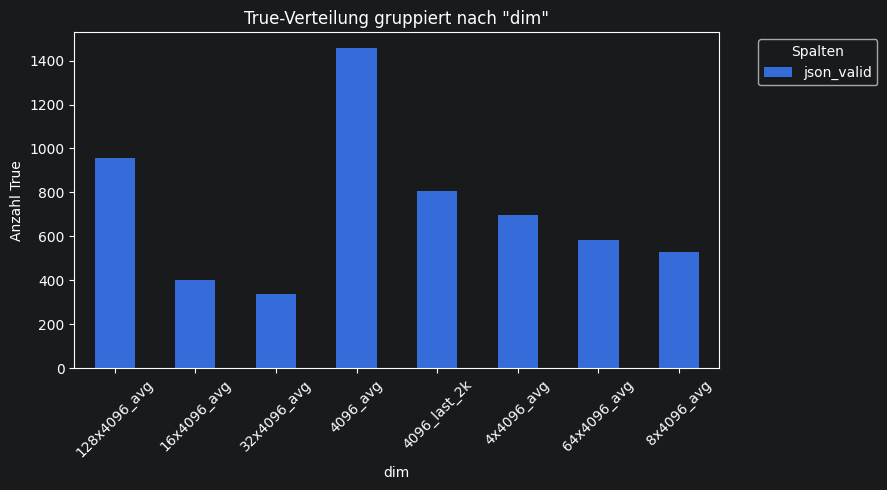

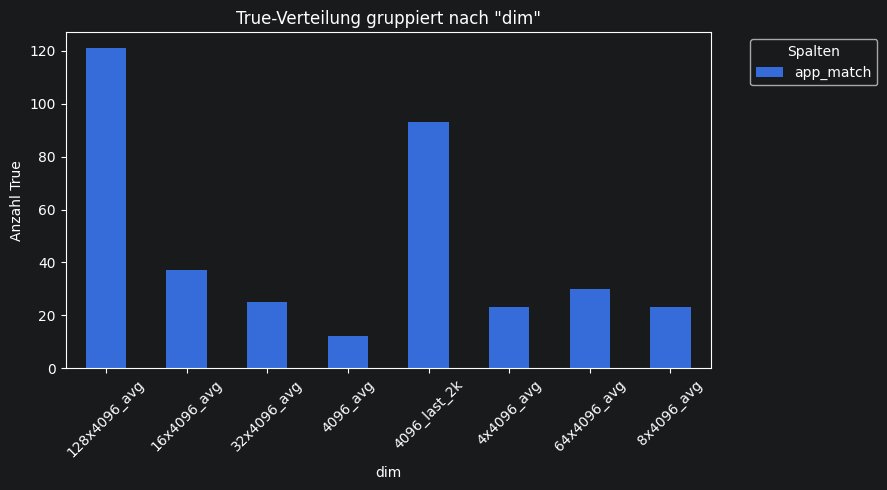

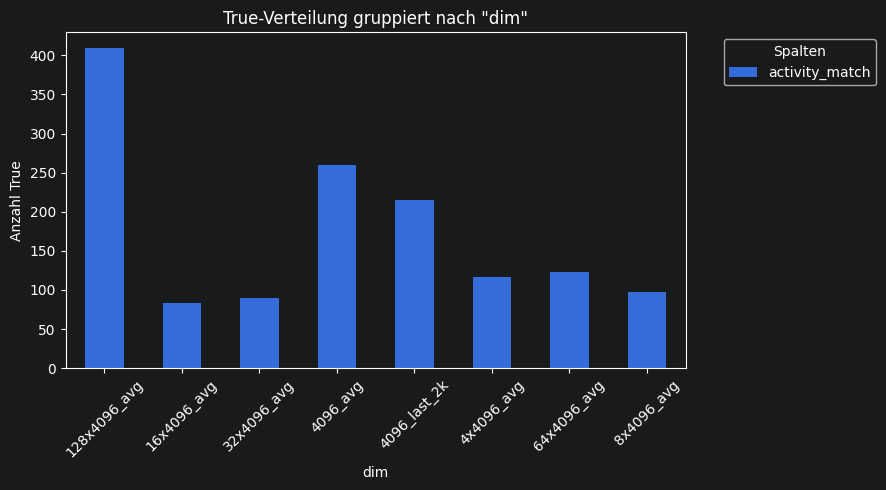

In [11]:
plot_bool_grouped(df, ['json_valid'], by="dim", as_percentage=False)
plot_bool_grouped(df, ['app_match'], by="dim", as_percentage=False)
plot_bool_grouped(df, ['activity_match'], by="dim", as_percentage=False)

               count      mean       std     min       25%      50%       75%  \
dim                                                                             
128x4096_avg  1546.0  0.333817  0.263204  0.0131  0.139200  0.25100  0.440625   
16x4096_avg   1546.0  0.095567  0.165989  0.0015  0.020450  0.03800  0.086025   
32x4096_avg   1546.0  0.086703  0.154011  0.0016  0.023800  0.04165  0.076500   
4096_avg      1546.0  0.152195  0.131493  0.0020  0.073550  0.11935  0.201675   
4096_last_2k  1546.0  0.135092  0.191838  0.0016  0.024525  0.06665  0.160775   
4x4096_avg    1546.0  0.106274  0.152520  0.0008  0.023525  0.05590  0.127650   
64x4096_avg   1546.0  0.113940  0.180837  0.0005  0.020625  0.05075  0.116675   
8x4096_avg    1546.0  0.097939  0.162586  0.0028  0.021325  0.04740  0.097075   

              max   median       IQR  
dim                                   
128x4096_avg  1.0  0.25100  0.301425  
16x4096_avg   1.0  0.03800  0.065575  
32x4096_avg   1.0  0.04165  0.052

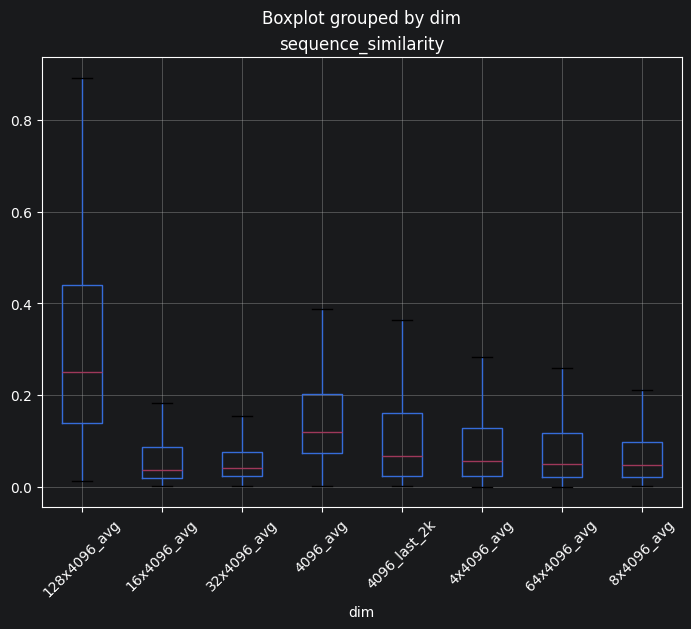

In [12]:
show_stats('sequence_similarity')

               count          mean           std  min      25%      50%  \
dim                                                                       
128x4096_avg  1546.0   1579.771669   1756.983594  0.0   423.00   1053.0   
16x4096_avg   1546.0  17550.533635   9905.689818  0.0  4888.25  22319.5   
32x4096_avg   1546.0  11622.555627   7999.439985  0.0  7521.25   9805.5   
4096_avg      1546.0   3691.230918   5234.358798  0.0  1294.00   2303.0   
4096_last_2k  1546.0  12225.608021  11079.215131  0.0  1493.00   6641.0   
4x4096_avg    1546.0  13840.698577  11472.980899  0.0  1466.50  20198.5   
64x4096_avg   1546.0  16298.359638  12585.162467  0.0  1921.00  21114.0   
8x4096_avg    1546.0  15894.394567  10468.049527  0.0  1365.00  22457.5   

                   75%      max   median       IQR  
dim                                                 
128x4096_avg   1968.00  16475.0   1053.0   1545.00  
16x4096_avg   23671.50  42908.0  22319.5  18783.25  
32x4096_avg   20351.25  32255.0   980

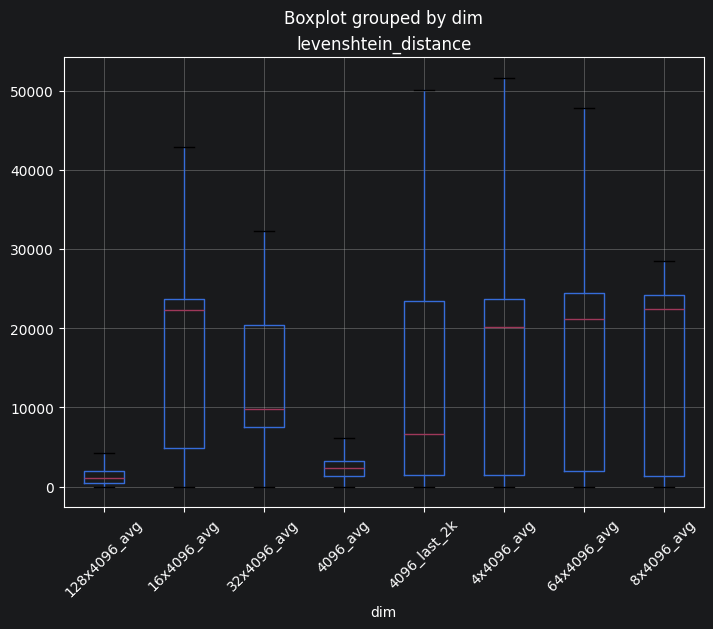

In [13]:
show_stats('levenshtein_distance')

               count      mean       std     min       25%      50%       75%  \
dim                                                                             
128x4096_avg  1546.0  0.581820  0.195501  0.0531  0.465625  0.56320  0.680550   
16x4096_avg   1546.0  0.190733  0.184352  0.0118  0.063800  0.12135  0.261100   
32x4096_avg   1546.0  0.166998  0.197442  0.0086  0.036825  0.07740  0.248325   
4096_avg      1546.0  0.356806  0.140772  0.0066  0.269675  0.36760  0.449675   
4096_last_2k  1546.0  0.261790  0.223596  0.0029  0.081600  0.19655  0.393175   
4x4096_avg    1546.0  0.239206  0.185720  0.0054  0.085725  0.19105  0.375050   
64x4096_avg   1546.0  0.224805  0.195078  0.0078  0.088300  0.17500  0.304925   
8x4096_avg    1546.0  0.213107  0.184953  0.0142  0.082250  0.15055  0.307075   

              max   median       IQR  
dim                                   
128x4096_avg  1.0  0.56320  0.214925  
16x4096_avg   1.0  0.12135  0.197300  
32x4096_avg   1.0  0.07740  0.211

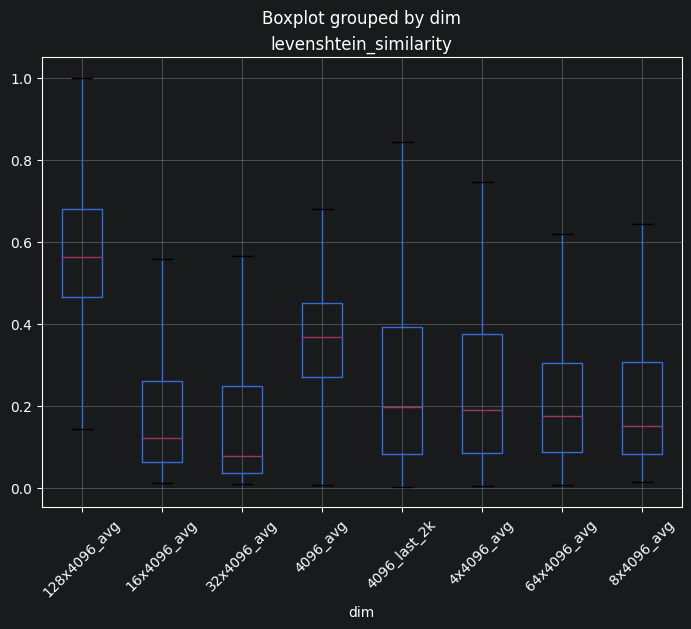

In [14]:
show_stats('levenshtein_similarity')

               count      mean       std  min  25%   50%      75%  max  \
dim                                                                      
128x4096_avg  1546.0  0.346669  0.372822  0.0  0.0  0.25  0.62995  1.0   
16x4096_avg   1546.0  0.050891  0.172678  0.0  0.0  0.00  0.00000  1.0   
32x4096_avg   1546.0  0.047307  0.166833  0.0  0.0  0.00  0.00000  1.0   
4096_avg      1546.0  0.146126  0.199055  0.0  0.0  0.04  0.25000  1.0   
4096_last_2k  1546.0  0.131839  0.260398  0.0  0.0  0.00  0.14290  1.0   
4x4096_avg    1546.0  0.072864  0.178967  0.0  0.0  0.00  0.00000  1.0   
64x4096_avg   1546.0  0.090340  0.220898  0.0  0.0  0.00  0.00000  1.0   
8x4096_avg    1546.0  0.046010  0.170798  0.0  0.0  0.00  0.00000  1.0   

              median      IQR  
dim                            
128x4096_avg    0.25  0.62995  
16x4096_avg     0.00  0.00000  
32x4096_avg     0.00  0.00000  
4096_avg        0.04  0.25000  
4096_last_2k    0.00  0.14290  
4x4096_avg      0.00  0.00000  
64x

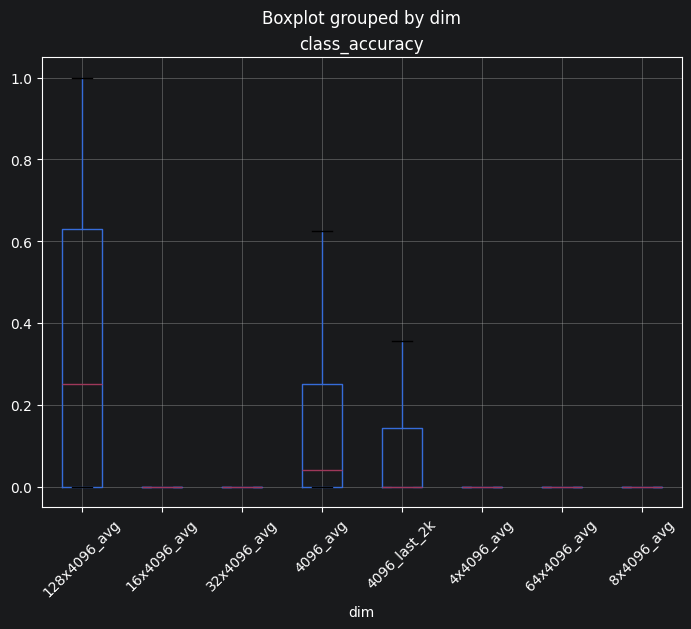

In [15]:
show_stats('class_accuracy')

               count      mean       std  min     25%     50%       75%  max  \
dim                                                                            
128x4096_avg  1546.0  0.211493  0.317681  0.0  0.0000  0.0541  0.265550  1.0   
16x4096_avg   1546.0  0.058942  0.191922  0.0  0.0000  0.0000  0.000000  1.0   
32x4096_avg   1546.0  0.041035  0.167379  0.0  0.0000  0.0000  0.000000  1.0   
4096_avg      1546.0  0.093690  0.164752  0.0  0.0138  0.0417  0.105675  1.0   
4096_last_2k  1546.0  0.102517  0.239525  0.0  0.0000  0.0004  0.070750  1.0   
4x4096_avg    1546.0  0.063098  0.176632  0.0  0.0000  0.0000  0.043200  1.0   
64x4096_avg   1546.0  0.078343  0.217197  0.0  0.0000  0.0000  0.019975  1.0   
8x4096_avg    1546.0  0.065919  0.207498  0.0  0.0000  0.0000  0.012925  1.0   

              median       IQR  
dim                             
128x4096_avg  0.0541  0.265550  
16x4096_avg   0.0000  0.000000  
32x4096_avg   0.0000  0.000000  
4096_avg      0.0417  0.091875  
4

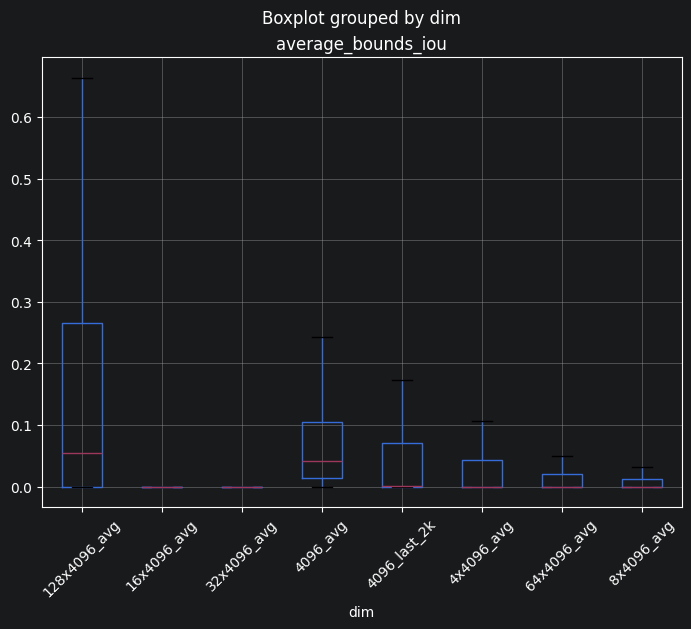

In [16]:
show_stats('average_bounds_iou')